# Day 4 — How do you know the answer was any good?

### What today is about

For three days you built systems that give answers. Today you learn to
**mark** those answers — like a teacher marks a test.

You will learn **six ways to mark an answer**. Then you will **trick each one
on purpose**, so you know when not to trust it.

### One sentence, all day

Almost every example today uses the same short story:

```
The cat sat on the mat.
```

Using one sentence lets you compare every score on the same answers.

### Two strange names

- **BLEU** (said "blue") = **B**i**L**ingual **E**valuation **U**nderstudy
- **ROUGE** (said "rouge") = **R**ecall-**O**riented **U**nderstudy for
  **G**isting **E**valuation

An **understudy** is the backup actor who plays the part when the star is
sick. Every score today is the same: **a backup for a human judge — never
the real judge.**

### How to use this notebook

- Run the cells **in order**, top to bottom.
- Each step has a note **before** the code (what and why), the **code**, and
  a note **after** it (what the output means).
- **Read both notes.** That is where the learning is.

**Remember:** a score is only a *guess* about quality. You test a guess by
trying to trick it.

## 1 · Setup

### Why start here?

Every later step needs the same tools, and step 9 needs some old books.
Getting them now means nothing stops in the middle of the lesson.

### What we are doing

- Installing two small libraries.
- Downloading free books from Project Gutenberg (for step 9).

Most of today is plain Python, so you can see how every number is made.

**2–3 minutes.**

In [1]:
!pip install -q nltk spacy
!python -m spacy download en_core_web_sm

import math, random
from collections import Counter

import nltk
nltk.download("gutenberg", quiet=True)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

random.seed(0)
print("ready")


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
     ---- ----------------------------------- 1.6/12.8 MB 7.0 MB/s eta 0:00:02
     ----------- ---------------------------- 3.7/12.8 MB 8.4 MB/s eta 0:00:02
     ---------------- ----------------------- 5.2/12.8 MB 8.2 MB/s eta 0:00:01
     --------------------- ------------------ 6.8/12.8 MB 7.8 MB/s eta 0:00:01
     -------------------------- ------------- 8.4/12.8 MB 7.7 MB/s eta 0:00:01
     ----------------------------- ---------- 9.4/12.8 MB 7.4 MB/s eta 0:00:01
     ------------------------------- -------- 10.2/12.8 MB 7.0 MB/s eta 0:00:01
     ----------------------------------- ---- 11.3/12.8 MB 6.7 MB/s eta 0:00:01
     ------------------------------------ --- 11.5/12.8 MB 6.4 MB/s eta 0:00:01
     ------------------------------------- -- 12.1/12.8 MB 5.8 MB/s eta 0:00:01
     -------------------------------------- - 12.3/12.8 MB 5.5

### What you just saw

```
ready
```

That is all it should print.

**If step 11 later says it can't find `en_core_web_sm`:** click
**Runtime → Restart session**, then run again from step 2. The download
worked — Python just started before it finished.

## 2 · Count runs of words

### Why do we need this?

BLEU and ROUGE both work the same way inside: they **count the words two
answers share.** This small helper does the counting. Steps 3 to 8 all use
it.

### What we are doing

Writing one helper that splits a sentence into **n-grams**.

An **n-gram** is just *n* words in a row. For *"The cat sat on the mat"*:

- **1-grams** (single words): `The` · `cat` · `sat` · `on` · `the` · `mat`
- **2-grams** (pairs): `The cat` · `cat sat` · `sat on` · `on the` · `the mat`

**Why pairs?** Single words show *which* words were used. Pairs also show a
little of the **order**.

**A word you will see in code and outputs: token.** A **token** is one piece
of text the computer counts as a word. Today that means anything between two
spaces — so `mat.` (with a full stop) is one token, and a lone `,` is a token
too.

**Instant.**

In [ ]:
def get_ngrams(text, order):
    """Counter of every n-gram of size `order` in `text`."""
    ngrams = Counter()
    words = text.split()
    for i in range(len(words) - order + 1):
        ngrams[" ".join(words[i:i + order])] += 1
    return ngrams

print(get_ngrams("The cat is on the mat", 1))
print(get_ngrams("The cat is on the mat", 2))

### What you just saw

```
Counter({'The': 1, 'cat': 1, 'is': 1, 'on': 1, 'the': 1, 'mat': 1})
Counter({'The cat': 1, 'cat is': 1, 'is on': 1, 'on the': 1, 'the mat': 1})
```

A `Counter` is a tally: each item, and how many times it appeared.

**Look closely: `The` and `the` are counted as two different words.**

The computer compares **letters**, not meaning. A capital letter makes a new
word. Remember this — it explains many surprises today.

## 3 · BLEU, with a pen

### Why learn BLEU?

Your translation app writes 10,000 sentences. You change the code. **Is it
better or worse?**

- A person could read all 10,000. That takes days and costs money — every
  time.
- **BLEU** is the cheap way. A person writes the correct answers **once**.
  After that, the computer marks every new version in seconds.

How? It counts how many of your words also appear in the correct answer.
**That is all.** It does not understand anything.

### Think of it like this

BLEU is a **lazy teacher**. They never read your sentence. They just tick
each of your words that is also on the answer key, and write a percentage.

### Why with a pen?

Count it once by hand, and the code in step 4 will not be a mystery. Two
minutes.

### Try it

- **Correct answer:** `The cat sat on the mat`
- **Your answer:** `The cat is on the mat`

```
single words in your answer:   the, cat, is, on, the, mat
  how many are in the correct answer?   ___ of 6      p1 = ___

pairs in your answer:   the cat, cat is, is on, on the, the mat
  how many are in the correct answer?   ___ of 5      p2 = ___
```

**Fill in the blanks before you read on.**

### The answer

```
p1 = 5/6 = 0.833      only "is" misses
p2 = 3/5 = 0.600      "cat is" and "is on" miss

BLEU-2 = 0.7071
```

### Why multiply, not average?

BLEU **multiplies** the two numbers, then takes the square root:
√(0.833 × 0.600) = **0.707**.

Why not just average them? Look at this answer — every word right, order
destroyed:

```
correct:   the cat sat on the mat
answer:    mat the on sat cat the

p1 = 6/6 = 1.000     every word is there
p2 = 0/5 = 0.000     no pair matches

average:    (1.000 + 0.000) / 2  = 0.500    "half right"?  No!
multiply:   √(1.000 × 0.000)     = 0.000    right - it is nonsense
```

**One zero makes the whole score zero.** Averaging would hide the problem.

## 4 · BLEU in code

### Why code it?

On paper you marked one sentence. Code can mark thousands in a second.

### What we are doing

Turning your pen-and-paper sum into a `bleu` function.

**Run the whole cell** — later steps use `bleu`.

The comments point out three small details that make BLEU correct. The most
important one — the **brevity penalty** — is explained after the output.

### What the code does

- `get_ngrams` (from step 2) lists the words and pairs in **your** answer.
- Each one is looked up in the **correct** answer. A word counts only as many
  times as it appears there — so *"the the the"* can't cheat.
- The results are **multiplied** (step 3), then the **brevity penalty** is
  applied.
- The last two lines score the step 3 example.

**Instant.**

In [ ]:
def bleu(hypothesis, references, max_order=4):
    """Modified-precision BLEU. Returns (score, [p1..pn], BP, c, r)."""
    hyp_words = hypothesis.split()
    c = len(hyp_words)
    if c == 0:
        return 0.0, [0.0] * max_order, 0.0, 0, 0

    # r = length of the correct answer, in words (with several, the one closest to yours)
    r = min((abs(len(ref.split()) - c), len(ref.split())) for ref in references)[1]

    ps = []
    for n in range(1, max_order + 1):
        hyp_ngrams = get_ngrams(hypothesis, n)
        total = sum(hyp_ngrams.values())          # total, NOT number of distinct
        if total == 0:
            ps.append(0.0)
            continue
        ceiling = Counter()                       # clip by max count in any reference
        for ref in references:
            for gram, k in get_ngrams(ref, n).items():
                if k > ceiling[gram]:
                    ceiling[gram] = k
        clipped = sum(min(k, ceiling[gram]) for gram, k in hyp_ngrams.items())
        ps.append(clipped / total)

    bp = 1.0 if c > r else math.exp(1 - r / c)    # the brevity penalty

    if min(ps) == 0:                              # never call log(0)
        return 0.0, ps, bp, c, r

    w = 1.0 / max_order
    return bp * math.exp(sum(w * math.log(p) for p in ps)), ps, bp, c, r


score, ps, bp, c, r = bleu("The cat is on the mat", ["The cat sat on the mat"], max_order=2)
print(f"BLEU-2 = {score:.4f}   p1={ps[0]:.4f}  p2={ps[1]:.4f}  BP={bp:.4f}  c={c}  r={r}")

### What you just saw

```
BLEU-2 = 0.7071   p1=0.8333  p2=0.6000  BP=1.0000  c=6  r=6
```

**The same numbers you got on paper.**

Three new things in that line:

- `c` = how many words **your** answer has (6)
- `r` = how many words the **correct** answer has (6)
- `BP` = the **brevity penalty** (1.0000 here)

### BP — the brevity penalty

**The problem:** BLEU only checks the words you said. It never checks if you
said **enough**. That allows an easy cheat:

```
correct answer:   the cat sat on the mat     (6 words)
cheat answer:     the                        (1 word)
```

1 word said, 1 word right = **100%**. A perfect score for one word!

**The fix:** if your answer is shorter than the correct one, BLEU multiplies
your score by a penalty:

```
your length     penalty    you keep
6 of 6 words    1.000      all of your score
5 of 6 words    0.819      about 4/5
3 of 6 words    0.368      about 1/3
1 of 6 words    0.007      almost nothing
```

The cheat now scores 1.000 × 0.007 = **0.007**.

**Rule: you can never raise BLEU by saying less.**

In our cell both answers have 6 words, so BP = 1 and changes nothing.

## 5 · Break BLEU

### The lesson

**BLEU checks the words, not the meaning.**

- Say the **right thing in different words** → **low** score.
- Say **nonsense with the right words** → **high** score.

So a BLEU score on its own can **never** tell you whether an answer is
correct.

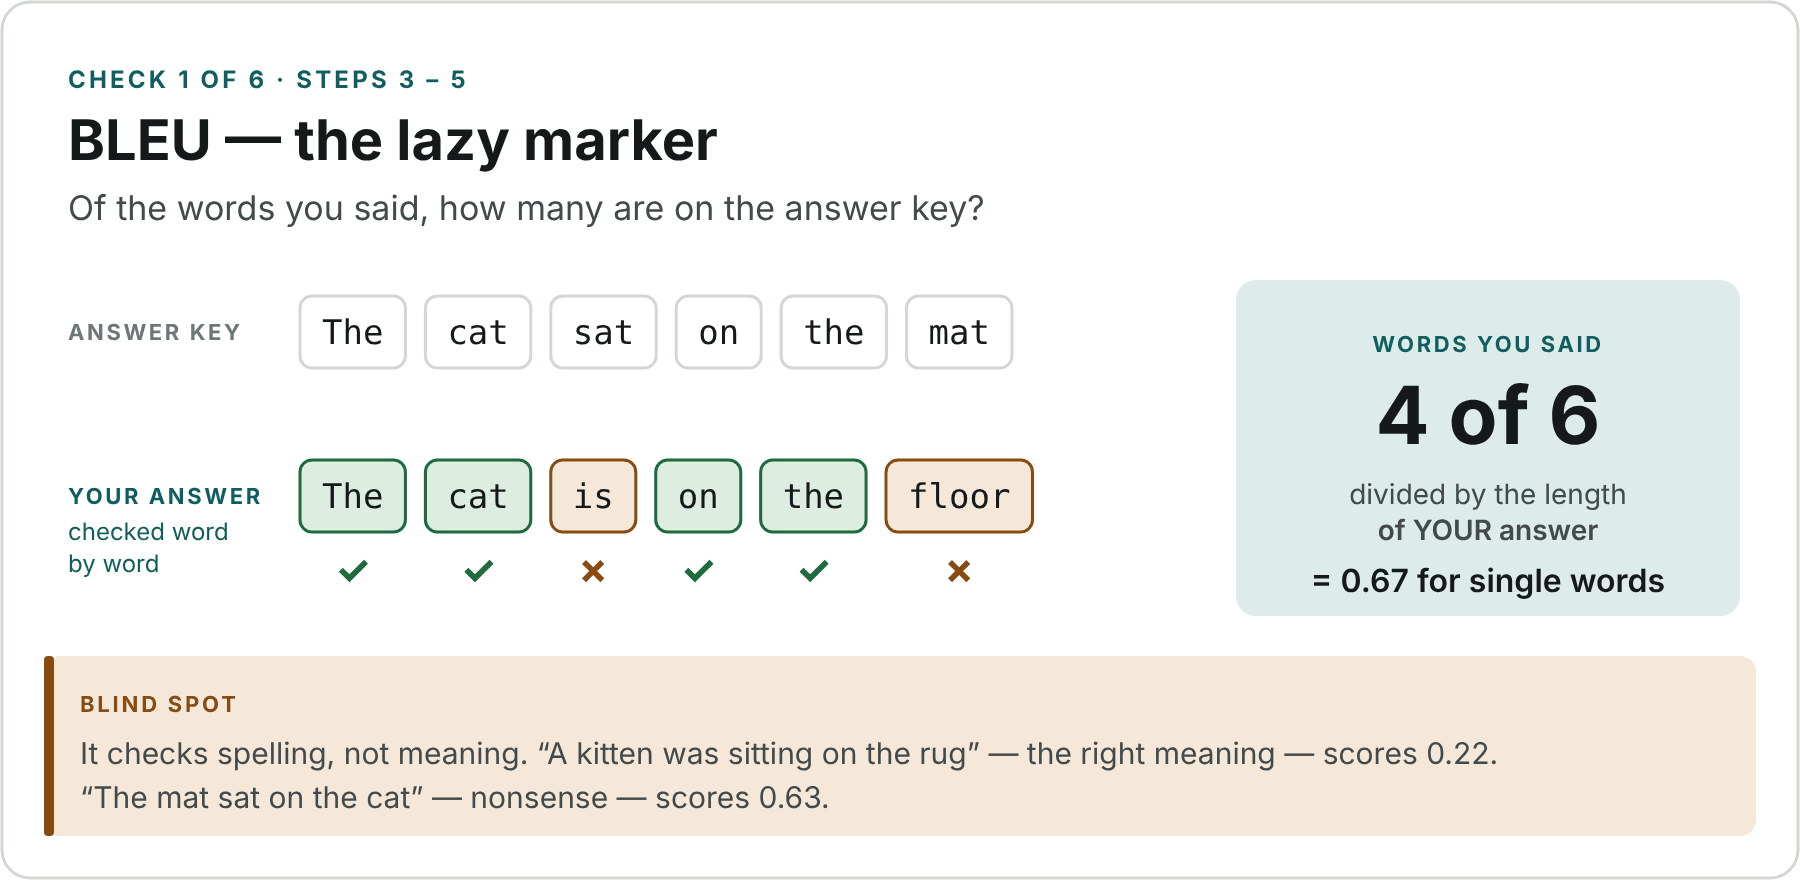

### Why break it?

Soon you will use scores to judge **your own** system. First you must know
when a score lies.

It is like testing a smoke alarm. Does it beep when there is smoke? Does it
stay quiet when there isn't?

### What we are doing

We give BLEU answers where **we already know** if they are right. Then we
check whether BLEU agrees.

Correct answer: **The cat sat on the mat**

| answer | really right? | a fair score |
| --- | --- | --- |
| `The cat sat on the mat` (a perfect copy) | yes | 1.0 |
| `A kitten was sitting on the rug` | **yes** — same meaning, other words | high |
| `The mat sat on the cat` | **no** — nonsense | low |

We use `max_order=2` (single words and pairs), like step 4.

**Guess the scores, then run it.**

**Instant.**

In [ ]:
correct = "The cat sat on the mat"

answers = [
    ("a perfect copy",             "The cat sat on the mat"),
    ("RIGHT meaning, other words", "A kitten was sitting on the rug"),
    ("WRONG meaning, same words",  "The mat sat on the cat"),
]

for label, answer in answers:
    s, ps, bp, c, r = bleu(answer, [correct], max_order=2)
    print(f"{s:.3f}   words {ps[0]:.3f}   pairs {ps[1]:.3f}   {label}")

### What you just saw

```
1.000   words 1.000   pairs 1.000   a perfect copy
0.218   words 0.286   pairs 0.167   RIGHT meaning, other words
0.632   words 1.000   pairs 0.400   WRONG meaning, same words
```

### How to read a line

- **first number** — the BLEU score, from 0 to 1
- **words** — the share of the answer's single words found in the correct
  answer
- **pairs** — the share of the answer's pairs found in the correct answer

### BLEU got both answers backwards

| answer | really | BLEU | fair? |
| --- | --- | --- | --- |
| a perfect copy | right | 1.000 | ✅ |
| `A kitten was sitting on the rug` | **right** | **0.218** | ❌ far too low |
| `The mat sat on the cat` | **wrong** | **0.632** | ❌ far too high |

The wrong answer scored about **3 times higher** than the right one.

### Why the right answer scored low

```
A ✗  kitten ✗  was ✗  sitting ✗  on ✓  the ✓  rug ✗       2 of 7 words
```

To BLEU, `kitten` and `cat` are just different letters. It doesn't know they
mean almost the same thing. The same goes for `sitting`/`sat` and
`rug`/`mat`.

### Why the wrong answer scored high

```
The ✓  mat ✓  sat ✓  on ✓  the ✓  cat ✓                   6 of 6 words
The mat ✗  mat sat ✗  sat on ✓  on the ✓  the cat ✗      2 of 5 pairs
```

Every word is right — just in a silly order. Only the pairs noticed, and not
enough. (`the cat` misses because the correct answer has `The cat` — the
capital letter again.)

Step 11 tries to fix this with a score that understands meaning.

## 6 · ROUGE — the opposite question

### Why another score?

BLEU was made for **translation**. Now think of **summaries**: a long text
goes in, a short one comes out.

A bad summary **leaves out** important points. BLEU can't see that — it only
checks what you *did* write. **ROUGE checks what you missed.**

### Think of it like this

ROUGE is a **packing list**. Before a trip you get a list: passport,
charger, toothbrush. Nobody cares that you also packed a book. They care
what you **forgot**.

### The one difference

| | asks | divides by |
| --- | --- | --- |
| **BLEU** | Of what I **said**, how much was right? | **my** answer's length |
| **ROUGE** | Of what I **should** say, how much did I say? | the **correct** answer's length |

### Two words you need

- **Recall** — of the things **on the list**, how many did you pack?
  *(Did I cover everything?)*
- **Precision** — of the things **you packed**, how many were on the list?
  *(Was it all needed?)*

**Always look at both.** Each one alone is easy to cheat (step 8).

### What we are doing

The cell builds three ROUGE functions — later steps use them. Then it scores
three answers against **The cat sat on the mat**:

| answer | what is special about it |
| --- | --- |
| `The cat sat on the mat` | a perfect copy |
| `The cat sat` | right, but stops halfway |
| `The cat sat.` | the same — plus a full stop |

We use **ROUGE-1** (single words). Step 7 shows the other kinds.

**Guess: will one full stop change the score?**

### What the code does

- `rouge_n` — counts the matching words, then divides two ways: by the
  **correct** answer (recall) and by **your** answer (precision).
- `lcs_length` and `rouge_l` — find the longest run of words in the same
  order. Step 7 uses them. **You don't need to follow these lines.**
- The bottom part scores our three answers.

**Instant.**

In [ ]:
def rouge_n(hyp, refs, n):
    """ROUGE-N (recall, precision, F1) against the best-overlapping reference."""
    hyp_ngrams = get_ngrams(hyp, n)
    best = {"overlap": 0, "ref_count": 0}
    for ref in refs:
        ref_ngrams = get_ngrams(ref, n)
        overlap = sum((hyp_ngrams & ref_ngrams).values())
        if overlap > best["overlap"]:
            best = {"overlap": overlap, "ref_count": sum(ref_ngrams.values())}

    hyp_count = sum(hyp_ngrams.values())
    recall    = best["overlap"] / best["ref_count"] if best["ref_count"] else 0.0
    precision = best["overlap"] / hyp_count if hyp_count else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return recall, precision, f1


def lcs_length(a, b):
    """Length of the longest common subsequence of two token lists."""
    dp = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i in range(len(a)):
        for j in range(len(b)):
            dp[i + 1][j + 1] = dp[i][j] + 1 if a[i] == b[j] else max(dp[i][j + 1], dp[i + 1][j])
    return dp[len(a)][len(b)]


def rouge_l(hyp, refs, beta=1.0):
    """ROUGE-L: n-grams swapped for the longest common subsequence, so word
    order counts without the words having to be next to each other."""
    best = {"f1": 0.0, "r": 0.0, "p": 0.0}
    hyp_tokens = hyp.split()
    for ref in refs:
        ref_tokens = ref.split()
        lcs = lcs_length(hyp_tokens, ref_tokens)
        r = lcs / len(ref_tokens) if ref_tokens else 0.0
        p = lcs / len(hyp_tokens) if hyp_tokens else 0.0
        denom = r + beta ** 2 * p
        f1 = (1 + beta ** 2) * p * r / denom if denom else 0.0
        if f1 > best["f1"]:
            best = {"f1": f1, "r": r, "p": p}
    return best["r"], best["p"], best["f1"]


correct = "The cat sat on the mat"

answers = [
    ("a perfect copy",            "The cat sat on the mat"),
    ("too short",                 "The cat sat"),
    ("too short, with full stop", "The cat sat."),
]

print("recall  precision  F1")
for label, answer in answers:
    r, p, f = rouge_n(answer, [correct], 1)
    print(f"{r:.3f}   {p:.3f}      {f:.3f}   {label}")

### What you just saw

```
recall  precision  F1
1.000   1.000      1.000   a perfect copy
0.500   1.000      0.667   too short
0.333   0.667      0.444   too short, with full stop
```

### How to read a line

- **recall** — how many of the 6 correct words the answer included
- **precision** — how many of the answer's own words are correct
- **F1** — the two mixed into one number

### `The cat sat`

```
recall:     The ✓  cat ✓  sat ✓  on ✗  the ✗  mat ✗     3 of 6 = 0.500
precision:  The ✓  cat ✓  sat ✓                        3 of 3 = 1.000
```

Together they say: **"everything it said is right — it just didn't say
enough."**

F1 (0.667) mixes the two, so you can't tell *what* went wrong. **Report
recall and precision, not just F1.**

### `The cat sat.` — one full stop

```
The ✓  cat ✓  sat. ✗
```

The code splits words at **spaces**. So `sat.` (with the dot) is a different
word from `sat`. Recall falls to **0.333** and precision to **0.667**.

**Same meaning — a third of the score gone, because of one dot.**

So when you share a ROUGE score, also say **how you split the words**.

## 7 · Optional — all three ROUGE scores on one sentence

### Why this step?

There are three kinds of ROUGE. Here you see all three on one example. You
also meet a word-counting detail that is easy to get wrong.

### What we are doing

A famous line from Dante's poem *Inferno*:

- **correct answer:** `All hope abandon , ye who enter here`
- **our answer:** `Abandon all hope , ye who enter here`

The same words — only the first three are in a different order.

### Before you run it

**Count the words in our answer.** Write the number down.

**Instant.**

In [ ]:
correct = "All hope abandon , ye who enter here"
answer  = "Abandon all hope , ye who enter here"

for n in (1, 2):
    r, p, f = rouge_n(answer, [correct], n)
    print(f"ROUGE-{n} -> recall {r:.3f}  precision {p:.3f}  F1 {f:.3f}")

r, p, f = rouge_l(answer, [correct])
print(f"ROUGE-L -> recall {r:.3f}  precision {p:.3f}  F1 {f:.3f}")

print()
print(answer.split())
print(len(answer.split()), "words")

### What you just saw

```
ROUGE-1 -> recall 0.750  precision 0.750  F1 0.750
ROUGE-2 -> recall 0.571  precision 0.571  F1 0.571
ROUGE-L -> recall 0.750  precision 0.750  F1 0.750

['Abandon', 'all', 'hope', ',', 'ye', 'who', 'enter', 'here']
8 words
```

### The three kinds

| kind | counts | score | why |
| --- | --- | --- | --- |
| **ROUGE-1** | single words | 0.750 | 6 of 8 words match |
| **ROUGE-2** | pairs | 0.571 | 4 of 7 pairs match |
| **ROUGE-L** | the longest run in the same order | 0.750 | 6 words line up in order |

**Which words miss?** `Abandon` and `all` — the correct answer has `abandon`
and `All`. Capital letters again.

**ROUGE-2 is lowest:** a pair only matches if **both words and their order**
match.

### How many words did you count?

Most people say **7**. The computer says **8** — the comma `,` has a space on
each side, so it counts as a word.

```
6 matches / 8 words = 0.750     what the code does
6 matches / 7 words = 0.857     what most people work out - wrong
```

**When you check a score by hand, count words the way the code does.**

## 8 · Break ROUGE

### The lesson

- **ROUGE forgives you for saying too much.** Add anything — even nonsense —
  and recall stays perfect. Only precision notices.
- **So always report recall and precision together.**
- **Like BLEU, ROUGE cannot see meaning.** Say the right thing in different
  words and both numbers are low.

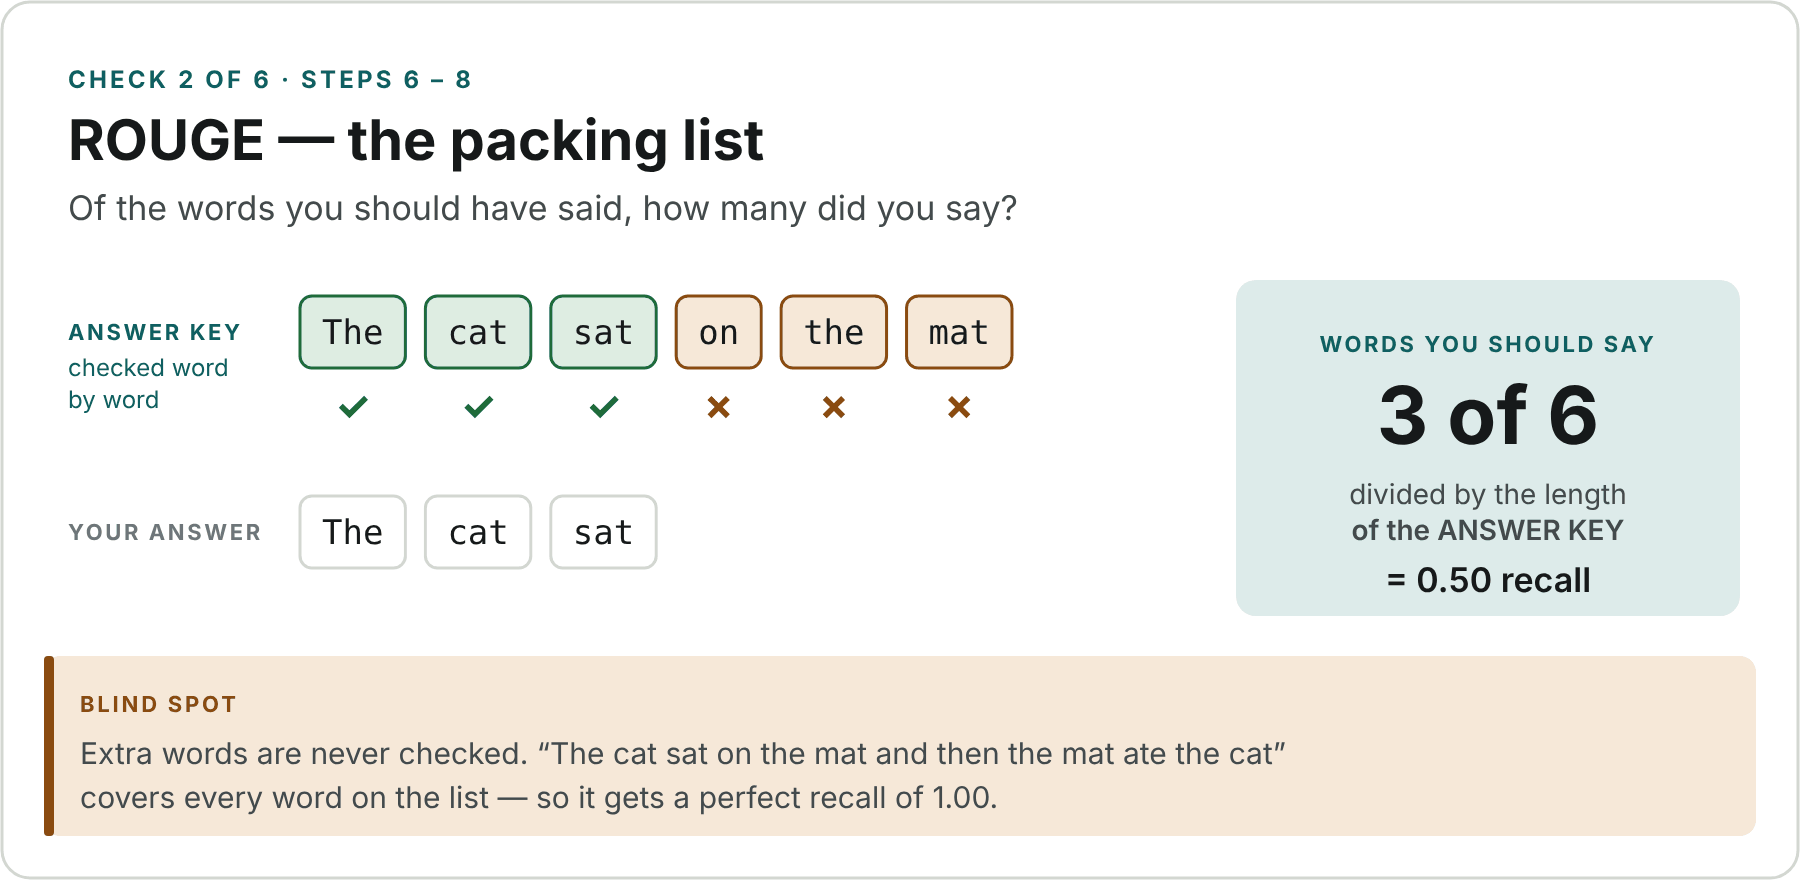

### Why break ROUGE too?

Same reason as step 5: before you trust a score, find out what fools it.
ROUGE looks the **opposite** way to BLEU — so it is fooled the opposite way.

### What we are doing

The same test as step 5. Correct answer: **The cat sat on the mat**

| answer | really right? | a fair score |
| --- | --- | --- |
| `The cat sat on the mat` (a perfect copy) | yes | 1.0 |
| `The cat sat on the mat and then the mat ate the cat` | **no** — right start, then nonsense | low |
| `A kitten was sitting on the rug` | **yes** — same meaning, other words | high |

ROUGE-1 again (single words). ROUGE's main number is **recall** — the R in
ROUGE.

**Guess, then run it.**

**Instant.**

In [ ]:
correct = "The cat sat on the mat"

answers = [
    ("a perfect copy",                "The cat sat on the mat"),
    ("WRONG: right words + nonsense", "The cat sat on the mat and then the mat ate the cat"),
    ("RIGHT meaning, other words",    "A kitten was sitting on the rug"),
]

print("recall  precision")
for label, answer in answers:
    r, p, f = rouge_n(answer, [correct], 1)
    print(f"{r:.3f}   {p:.3f}      {label}")

### What you just saw

```
recall  precision
1.000   1.000      a perfect copy
1.000   0.462      WRONG: right words + nonsense
0.333   0.286      RIGHT meaning, other words
```

### Recall got both answers backwards

| answer | really | recall | fair? |
| --- | --- | --- | --- |
| a perfect copy | right | 1.000 | ✅ |
| `...and then the mat ate the cat` | **wrong** | **1.000** | ❌ a perfect score for nonsense |
| `A kitten was sitting on the rug` | **right** | **0.333** | ❌ far too low |

### Why nonsense got a perfect recall

Recall only asks: *is every word of the correct answer in there?*

```
The ✓  cat ✓  sat ✓  on ✓  the ✓  mat ✓       6 of 6 = 1.000
```

Yes, all six. The extra words — *and then the mat ate the cat* — are **never
checked.** You can add anything, even a lie.

### Precision caught it

Precision looks at the answer's own 13 words. Only 6 of them are needed:

```
6 needed / 13 words = 0.462
```

**This is why you always report recall and precision together.**

### Why the right answer scored low

```
The ✗  cat ✗  sat ✗  on ✓  the ✓  mat ✗       2 of 6 = 0.333
```

Like BLEU, ROUGE compares **spelling**. `kitten` is not `cat`.

### BLEU and ROUGE, side by side

- **BLEU** punishes saying **too little** (the brevity penalty).
- **ROUGE** forgives saying **too much**.
- **Neither one can see meaning.**

## 9 · Train your own language model

### Why?

BLEU and ROUGE need a **correct answer** to compare with. Often you don't
have one — nobody wrote the right reply to every question a chatbot will
get.

**Perplexity** scores text **without** a correct answer. But it needs a
language model — so we build a tiny one.

### What perplexity is

Think of your phone's **autocomplete**:

- Type *"once upon a"* → it is sure the next word is *"time"*. **Low
  perplexity** — not surprised.
- Type *"purple elephant quantum"* → it has no idea what comes next. **High
  perplexity** — very surprised.

Perplexity is roughly **how many words the model is choosing between.**
2 = confident. 800 = lost.

**Lower = less surprised.**

### What this cell builds

So far we compared short answers. Now the model must learn **what normal
English looks like** — and for that it needs a lot of text. So we use whole
novels.

A model made only of **counts**: how often each word, each pair and each
group of three words appears in 2.4 million words of old novels.

**That is all the training is — counting.** No neural network.

**One book is kept out**, so later we can test on text the model has never
seen.

### What the code does

- Load the old novels, leaving one book (*Emma*) out.
- Keep words seen 3 or more times. All rarer words become `<unk>`
  (unknown).
- `prep` adds `<s>` (start) and `</s>` (end) marks to each sentence.
- The loop counts every word, pair and group of three. **These counts are
  the model.**

**About 30 seconds.**

In [ ]:
from nltk.corpus import gutenberg

HELD_OUT = "austen-emma.txt"
train_sents = [[w.lower() for w in s]
               for book in gutenberg.fileids() if book != HELD_OUT
               for s in gutenberg.sents(book)]
print(f"training sentences: {len(train_sents):,}")

counts = Counter(w for s in train_sents for w in s)
VOCAB = {w for w, c in counts.items() if c >= 3}       # rare words become <unk>
print(f"vocab (seen 3+ times): {len(VOCAB):,}   tokens: {sum(counts.values()):,}")

def prep(tokens):
    return ["<s>", "<s>"] + [w if w in VOCAB else "<unk>" for w in tokens] + ["</s>"]

tri, bi, uni = Counter(), Counter(), Counter()
for s in train_sents:
    t = prep(s)
    for i, w in enumerate(t):
        uni[w] += 1
        if i >= 1: bi[(t[i - 1], w)] += 1
        if i >= 2: tri[(t[i - 2], t[i - 1], w)] += 1

N_TOK = sum(uni.values())
V_SIZE = len(VOCAB) + 3
print("counts built")

### What you just saw

```
training sentences: 90,800
vocab (seen 3+ times): 20,630   tokens: 2,429,301
counts built
```

- **90,800** sentences read
- **20,630** different words kept

**Why keep only words seen 3 or more times?** Rare words are mostly typos and
names. They make the model bigger, not better. All rare words become one
**"unknown"** word.

**Why an "unknown" word?** Without it, a new word would get a chance of
**zero** — and perplexity would be **infinity**.

## 10 · Measure perplexity

### The lesson

**Perplexity measures familiarity, not truth.**

- A false sentence made of **familiar** phrases — *"the cat sat on the
  floor"* — scores **better** than a true one with an **unfamiliar** phrase —
  *"the cat sat on the mat"*.
- Low perplexity means *"this looks like text I have seen"* — **never**
  *"this is true"*.

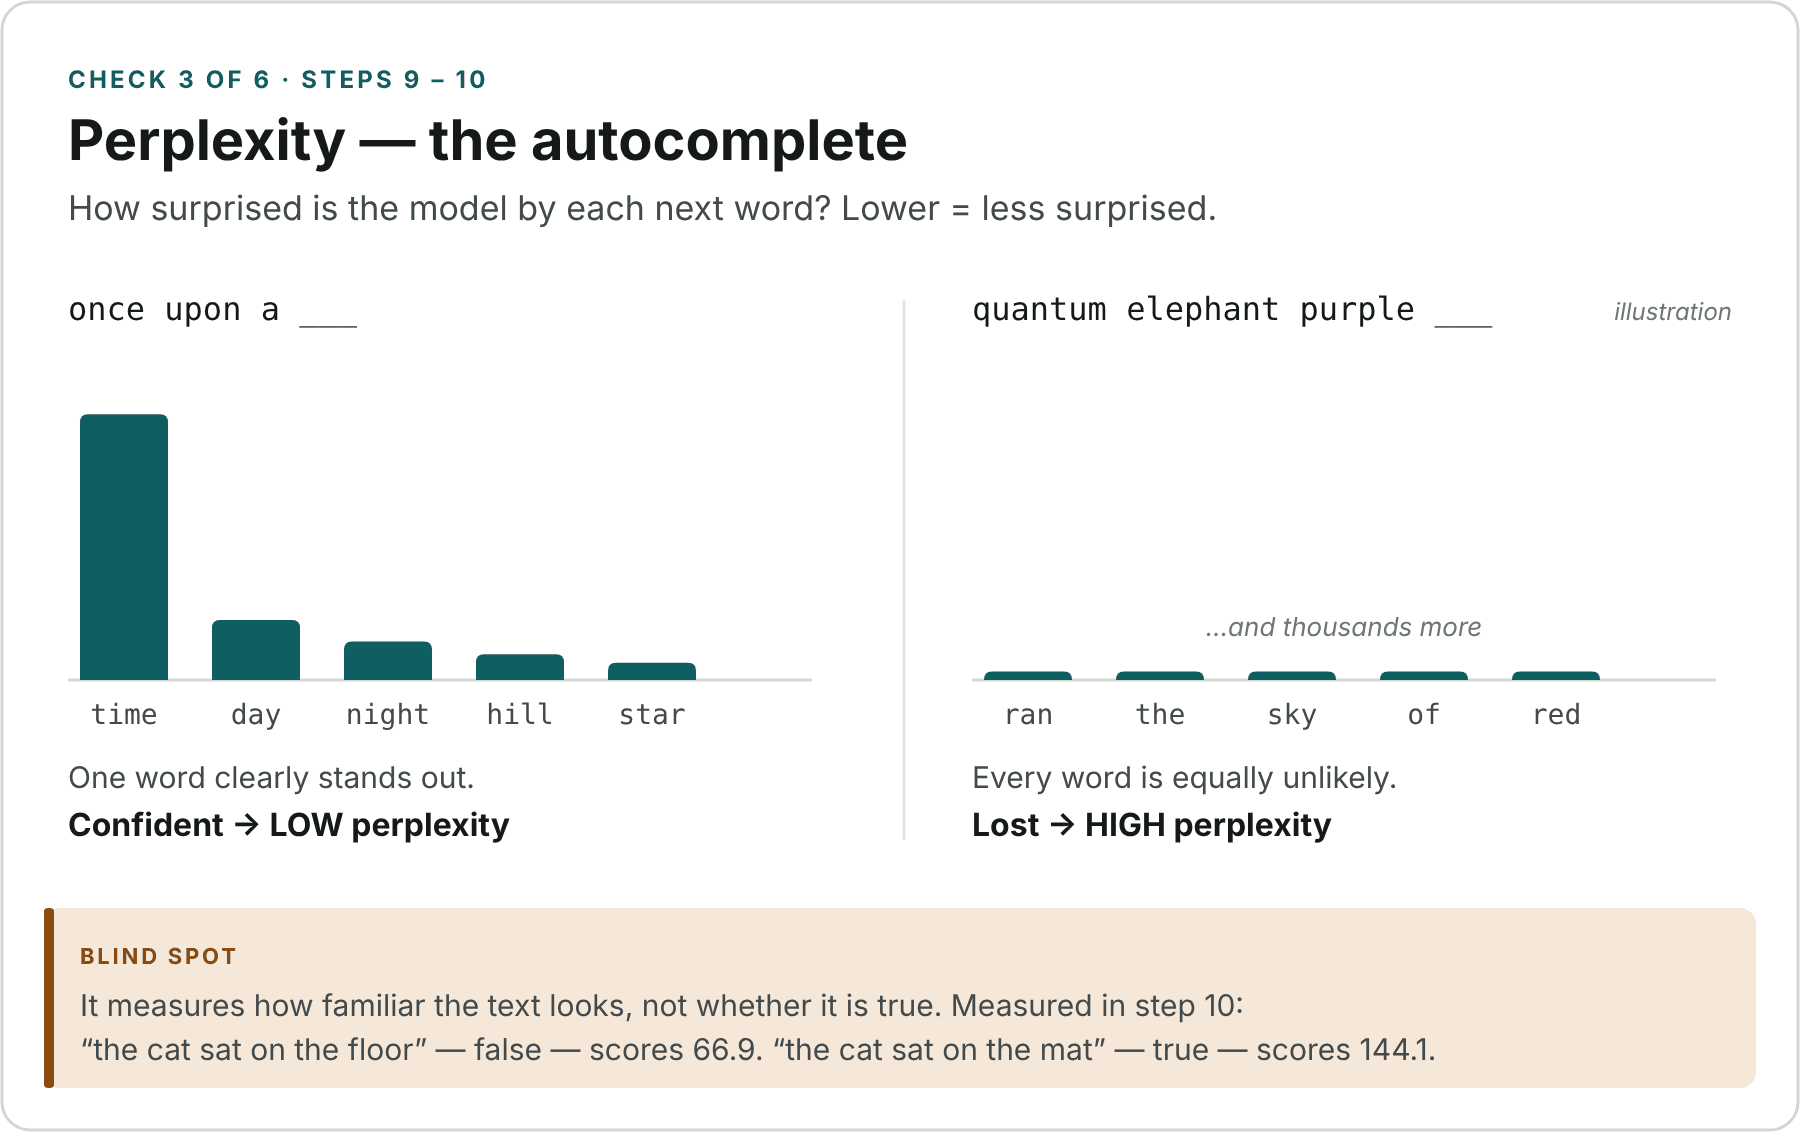

### Why these seven sentences?

Each sentence tests one thing. The last three are about our cat, and ask the
big question: **can perplexity tell true from false?**

### What we are doing

Scoring seven sentences with your model. **Lower = less surprised.**

The first four:

- ordinary English
- real text from the book the model never saw
- the same words, shuffled
- random words

The last three — our story is *"The cat sat on the mat."*:

- `the cat sat on the mat` — **true**
- `the cat sat on the floor` — **false**, but sounds normal
- `the mat sat on the cat` — **nonsense** (it fooled BLEU in step 5)

**Guess which of the last three gets the best (lowest) score. Then run it.**

### What the code does

- `p_word` — the chance of a word, given the two words before it. It mixes
  the counts of threes, pairs and single words (60% / 30% / 10%).
- `perplexity` — goes word by word and averages how surprised the model is.
- The bottom part scores the seven sentences.

**A few seconds.**

In [ ]:
def p_word(w2, w1, w):
    """P(w | w2 w1), interpolating trigram / bigram / add-1 unigram at 0.6 / 0.3 / 0.1."""
    p3 = tri[(w2, w1, w)] / bi[(w2, w1)] if bi[(w2, w1)] else 0.0
    p2 = bi[(w1, w)] / uni[w1] if uni[w1] else 0.0
    p1 = (uni[w] + 1) / (N_TOK + V_SIZE)        # the floor: nothing is ever impossible
    return 0.6 * p3 + 0.3 * p2 + 0.1 * p1

def perplexity(text):
    t = prep(nltk.word_tokenize(text.lower()))
    logp = sum(math.log(p_word(t[i - 2], t[i - 1], t[i])) for i in range(2, len(t)))
    return math.exp(-logp / (len(t) - 2))

samples = [
    ("ordinary English",       "he could not help but smile at the thought of it ."),
    ("held-out real prose",    "she was the youngest of the two daughters of a most affectionate father ."),
    ("same words, shuffled",   "thought the smile of it could he not but at help ."),
    ("random words",           "bicycle quantum elephant the of purple ran ."),
    ("TRUE: the story",        "the cat sat on the mat ."),
    ("FALSE: floor, not mat",  "the cat sat on the floor ."),
    ("NONSENSE: from step 5",  "the mat sat on the cat ."),
]
for label, s in samples:
    print(f"{perplexity(s):10.1f}   {label}")

### What you just saw

```
      42.8   ordinary English
      71.1   held-out real prose
     276.2   same words, shuffled
     807.0   random words
     144.1   TRUE: the story
      66.9   FALSE: floor, not mat
     135.8   NONSENSE: from step 5
```

### The first four make sense

Ordinary English is easy (**42.8**). Shuffle the same words and it is six
times worse (**276.2**). Random words are worst (**807.0**). So perplexity
**does** notice word order.

### The cat sentences don't

| sentence | really | perplexity |
| --- | --- | --- |
| `the cat sat on the floor` | **false** | **66.9** — the best |
| `the mat sat on the cat` | nonsense | 135.8 |
| `the cat sat on the mat` | **true** | **144.1** — the worst |

**The true sentence got the worst score.**

### Why?

The model learned from old novels. In those books:

```
"on the floor"   26 times
"on the mat"      0 times
```

It has seen *on the floor* many times, and *on the mat* never. So the true
sentence looks **strange** to it. The model doesn't know our story — it only
knows what is **familiar**.

**Perplexity measures familiarity, not truth.**

## 10b · Optional — the number you would actually quote

### Why a whole book?

One sentence can be picked to make a model look good. A fair number comes
from **a lot of text the model has never seen.**

### What we are doing

Measuring perplexity on the whole book we kept out of training.

**A few seconds.**

In [ ]:
held = [w.lower() for s in gutenberg.sents(HELD_OUT)[:400] for w in s]
t = prep(held)
logp = sum(math.log(p_word(t[i - 2], t[i - 1], t[i])) for i in range(2, len(t)))
print(f"held-out Emma, {len(t) - 3:,} tokens -> perplexity {math.exp(-logp / (len(t) - 2)):.1f}")

### What you just saw

```
held-out Emma, 11,018 tokens -> perplexity 284.6
```

**284.6** on a whole book. **42.8** on one hand-picked sentence. **Same
model!**

So when someone says *"our model has perplexity 42"*, ask: **"On what
text?"** A perplexity number without its text means nothing.

## 11 · Compare meanings, not words

### The lesson

**A meaning score rewards the right thing said in different words** —
`child` can match `boy`, and `happy` can match `joyful`.

**But it compares one word at a time.** A single `not` flips the meaning of
a sentence and barely changes the score.

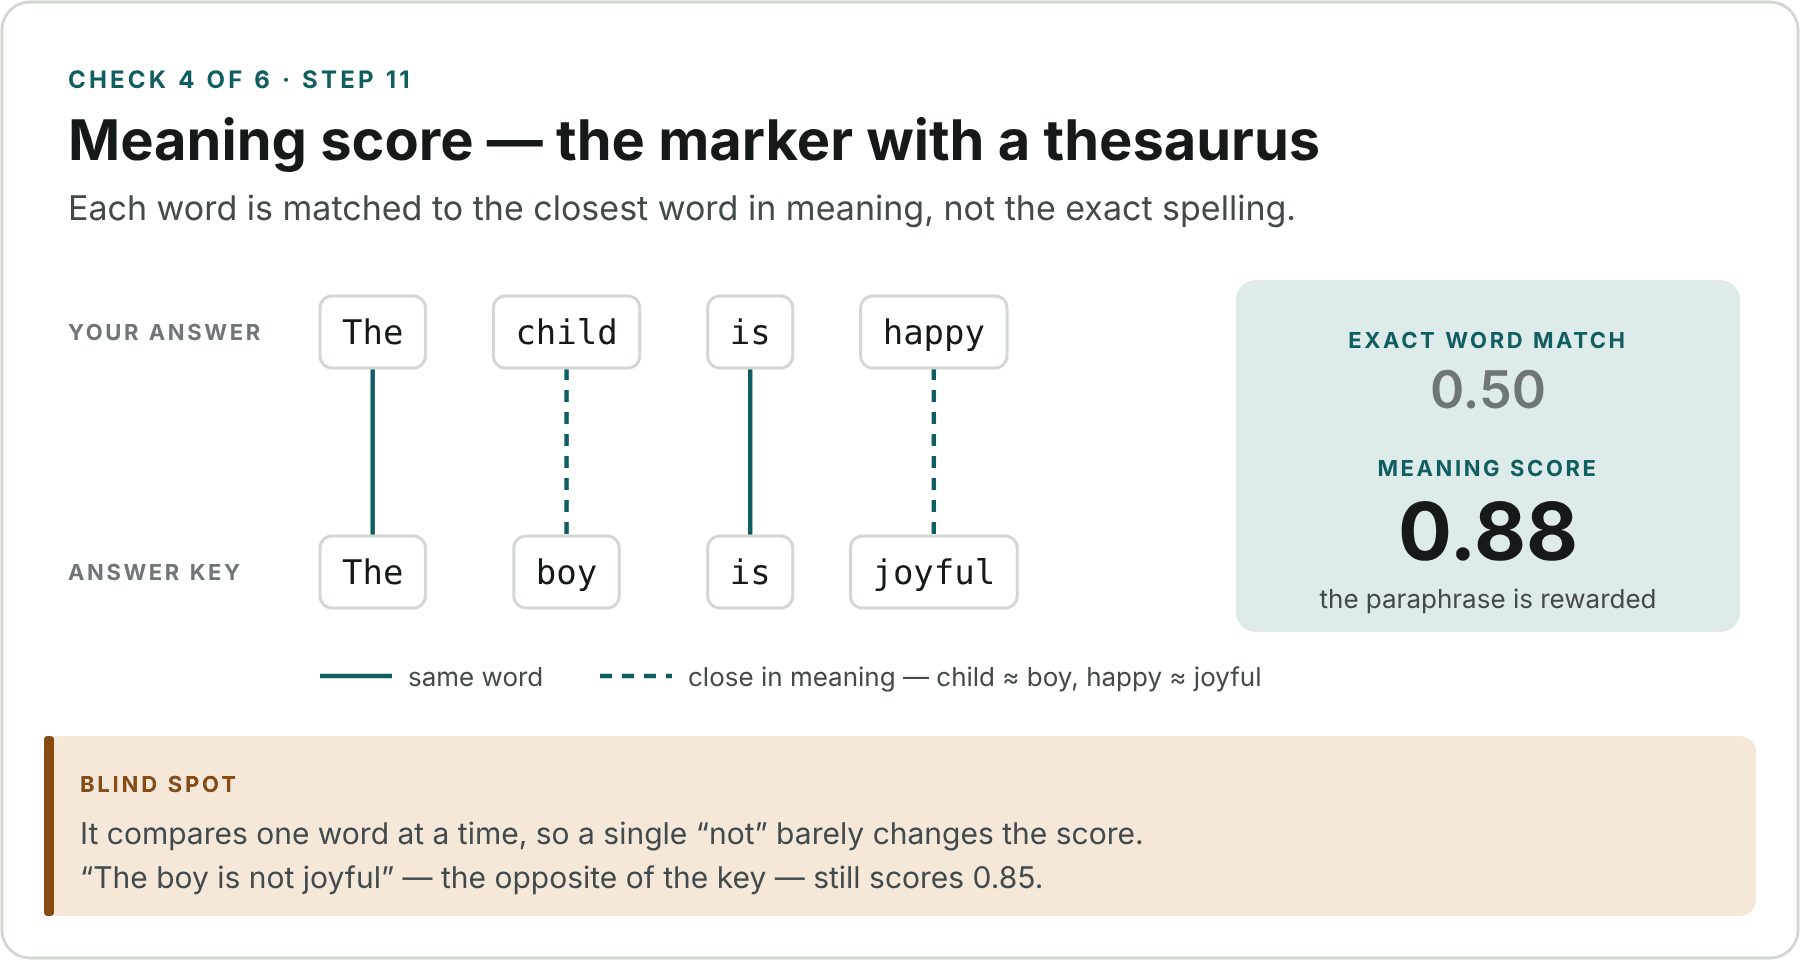

### Why score meaning?

In steps 5 and 8 the kitten answer was **right** but scored low. BLEU and
ROUGE only match exact spelling. We need a score that knows `child` and
`boy` mean nearly the same.

### Think of it like this

The lazy teacher from step 3 now has a **thesaurus**. Each of your words may
match the **closest word in meaning** on the answer key:
`child` ↔ `boy`, `happy` ↔ `joyful`.

### How it works

1. Turn each word into a list of numbers that stands for its meaning.
2. Compare each word of the answer with each word of the correct answer.
3. Keep each word's best match, and average.

A real score called **BERTScore** works this way. Ours is a small, fast
copy.

### What we are doing

Five answers, each next to its correct answer:

| row | answer | correct answer |
| --- | --- | --- |
| synonyms | The child is happy. | The boy is joyful. |
| reworded | Power was lost due to a storm. | A storm caused power outages. |
| NEGATED | The boy is **not** joyful. | The boy is joyful. |
| opposite | The boy is **sad**. | The boy is joyful. |
| identical | The boy is joyful. | The boy is joyful. |

We print BLEU's word score next to the new meaning score.

**Watch rows 3 and 4 — they mean the opposite of the correct answer.**

### What the code does

- Load a small spaCy model that turns each word into a list of numbers.
- `greedy_match` — compares every word of the answer with every word of the
  correct answer, keeps each word's best match, and averages.
- `unigram_precision` — the plain word match from step 3, to compare.
- The bottom part scores the five pairs.

**About a minute the first time.**

In [ ]:
import spacy, numpy as np
nlp = spacy.load("en_core_web_sm")

def greedy_match(cand, ref):
    """Precision / recall / F1 by matching contextual token vectors."""
    c = [t for t in nlp(cand) if not t.is_punct]
    r = [t for t in nlp(ref) if not t.is_punct]

    def unit(tok):
        v = tok.vector
        n = np.linalg.norm(v)
        return v / n if n else v

    S = np.array([unit(t) for t in c]) @ np.array([unit(t) for t in r]).T
    P = S.max(axis=1).mean()      # each answer word's best match
    R = S.max(axis=0).mean()      # each reference word's best match
    return P, R, (2 * P * R / (P + R) if (P + R) else 0.0)

def unigram_precision(hyp, ref):
    """BLEU's p1, for contrast."""
    a, b = get_ngrams(hyp, 1), get_ngrams(ref, 1)
    total = sum(a.values())
    return sum(min(k, b[g]) for g, k in a.items()) / total if total else 0.0

pairs = [
    ("synonyms",         "The child is happy.",            "The boy is joyful."),
    ("reworded",         "Power was lost due to a storm.", "A storm caused power outages."),
    ("NEGATED",          "The boy is not joyful.",         "The boy is joyful."),
    ("opposite meaning", "The boy is sad.",                "The boy is joyful."),
    ("identical",        "The boy is joyful.",             "The boy is joyful."),
]
print(f"{'':18} {'p1 (BLEU)':>10} {'greedy F1':>10}")
for label, cand, ref_ in pairs:
    print(f"{label:18} {unigram_precision(cand, ref_):10.4f} {greedy_match(cand, ref_)[2]:10.4f}")

### What you just saw

```
                    p1 (BLEU)  greedy F1
synonyms               0.5000     0.8814
reworded               0.0000     0.3795
NEGATED                0.8000     0.8525
opposite meaning       0.7500     0.9314
identical              1.0000     1.0000
```

### How to read it

- **p1 (BLEU)** — exact word match, like step 3
- **greedy F1** — the new meaning score

Both go from 0 to 1.

### Row 1 — what we wanted

*"The child is happy"* vs *"The boy is joyful"*: word match **0.50**,
meaning **0.88**. Different words, same meaning — and now it scores well.

### Rows 3 and 4 — the hole

| answer | means | meaning score |
| --- | --- | --- |
| The child is happy. | the **same** | 0.88 |
| The boy is **not** joyful. | the **opposite** | **0.85** |
| The boy is **sad**. | the **opposite** | **0.93** |

**"The boy is sad" scores higher than the correct answer in row 1!**

**Why?**

- It works **one word at a time.** `not` is 1 word out of 5 — the other 4
  match perfectly.
- `sad` and `joyful` appear in the same kinds of sentences, so their numbers
  are close — even though they mean opposite things.

### The other two rows

- **reworded** — a real paraphrase. No exact word matches (0.00 — even
  `Power` and `power` differ by a capital letter), but meaning gives
  **0.38**. Better, not perfect.
- **identical** — the check that it works: **1.00** on both.

Real BERTScore has the same weakness. **If the answer is yes or no, safe or
unsafe, a meaning score may not notice the model said the opposite.**

## 12 · Ask a human — properly

### The lesson

**A person is the only check that judges whether an answer is actually
right.**

- Give them a **scoring sheet with an example for every level**, so everyone
  marks the same way.
- **Measure whether two people agree** (kappa) before you trust the result.
- It is **slow and expensive** — you cannot do it after every change.

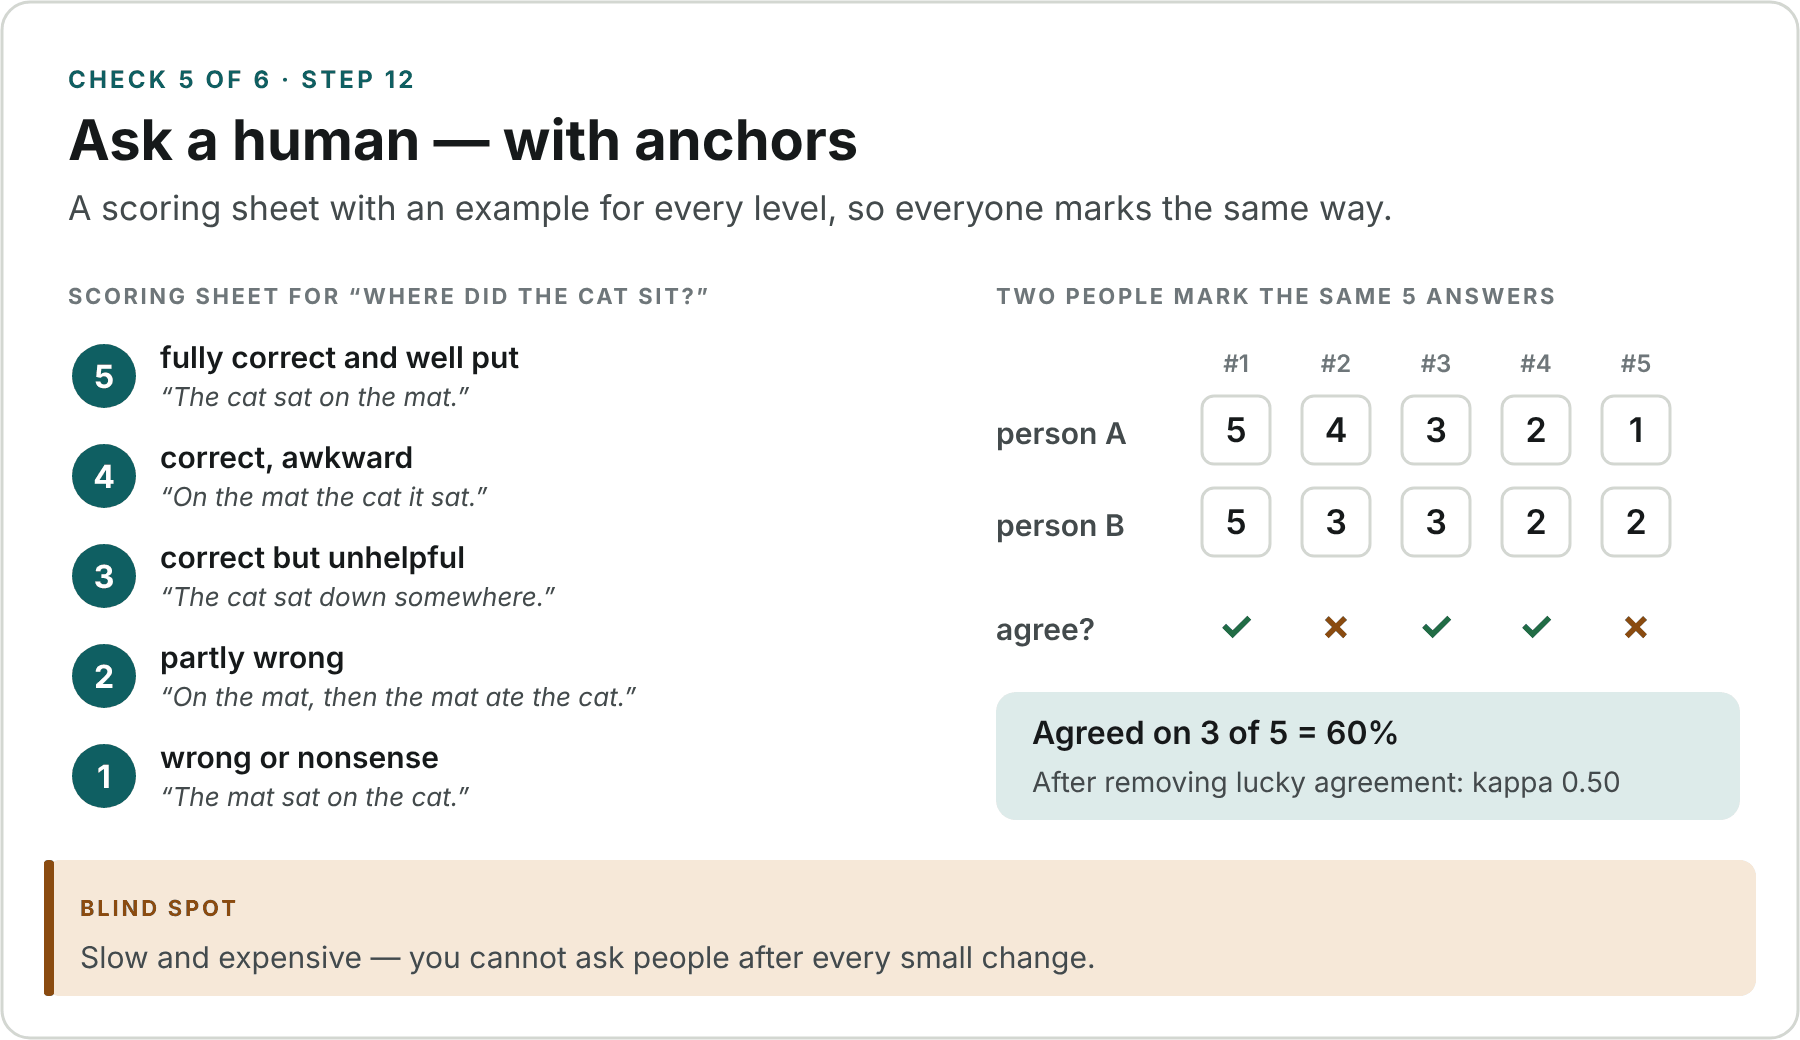

### Why ask a person?

Every score so far is a **stand-in** for a person — and every one was
fooled. A person is the real judge. But only if you ask the **right way**.

### The problem

Ask ten people *"rate this out of 5"* and you get ten different scales. One
person's 3 is another person's 5.

### The fix: an example for every level

Give people a **scoring sheet** with an example for each score: *"a 5 looks
like this, a 3 looks like this."* Now everyone marks the same way.

### What we are doing

- Printing a scoring sheet for the question **"Where did the cat sit?"**
  (story: *The cat sat on the mat.*)
- Checking whether two people who used it **agree**.

### What the code does

- `RUBRIC` — the scoring sheet: one example answer for each score.
- `rater_a` and `rater_b` — the marks two people gave the same five answers.
- `cohens_kappa` — compares how often they agreed with how often luck alone
  would agree.

**Instant.**

In [ ]:
QUESTION = "Where did the cat sit?"          # the story: "The cat sat on the mat."

RUBRIC = {
    5: ("fully correct and well put",   "The cat sat on the mat."),
    4: ("correct, awkward",             "On the mat the cat it sat."),
    3: ("correct but unhelpful",        "The cat sat down somewhere."),
    2: ("partly wrong",                 "On the mat, then the mat ate the cat."),
    1: ("wrong or nonsense",            "The mat sat on the cat."),
}
print(f"Question: {QUESTION}\n")
for k in sorted(RUBRIC, reverse=True):
    label, example = RUBRIC[k]
    print(f"{k}  {label:<28} e.g. {example!r}")

rater_a = [5, 4, 3, 2, 1]
rater_b = [5, 3, 3, 2, 2]

def cohens_kappa(a, b):
    n = len(a)
    po = sum(x == y for x, y in zip(a, b)) / n
    ca, cb = Counter(a), Counter(b)
    pe = sum(ca[k] / n * cb[k] / n for k in set(a) | set(b))
    return (po - pe) / (1 - pe)

print(f"\nobserved agreement {sum(x == y for x, y in zip(rater_a, rater_b)) / len(rater_a):.2f}"
      f"   kappa {cohens_kappa(rater_a, rater_b):.3f}")

### What you just saw

```
Question: Where did the cat sit?

5  fully correct and well put   e.g. 'The cat sat on the mat.'
4  correct, awkward             e.g. 'On the mat the cat it sat.'
3  correct but unhelpful        e.g. 'The cat sat down somewhere.'
2  partly wrong                 e.g. 'On the mat, then the mat ate the cat.'
1  wrong or nonsense            e.g. 'The mat sat on the cat.'

observed agreement 0.60   kappa 0.500
```

### Look at levels 2 and 1

- *"…then the mat ate the cat"* got a **perfect** ROUGE recall in step 8.
- *"The mat sat on the cat"* got **0.63** on BLEU in step 5.

A person puts both **at the bottom**, straight away.

### Did the two people agree?

```
person A:   5   4   3   2   1
person B:   5   3   3   2   2
            ✓   ✗   ✓   ✓   ✗      agree on 3 of 5 = 0.60
```

But two people **guessing at random** would also agree sometimes, by luck —
with these marks, about **20%** of the time. **Kappa** counts only the
agreement above luck:

```
kappa = (60% - 20%) / (100% - 20%) = 40 / 80 = 0.500
```

- **1.0** = perfect agreement
- **0.0** = no better than guessing

Here kappa is **0.500** — only "moderate", even with a scoring sheet and five
easy answers.

**Check kappa before you trust people's scores. If it is low, fix the
scoring sheet, not the people.**

## 13 · Go looking for the failure

### The lesson

**An average score hides the questions your system gets wrong.**

- Write those questions down **on purpose**, keep them, and **re-run every
  one after every change**.
- It only catches the failures **you thought to write down**.

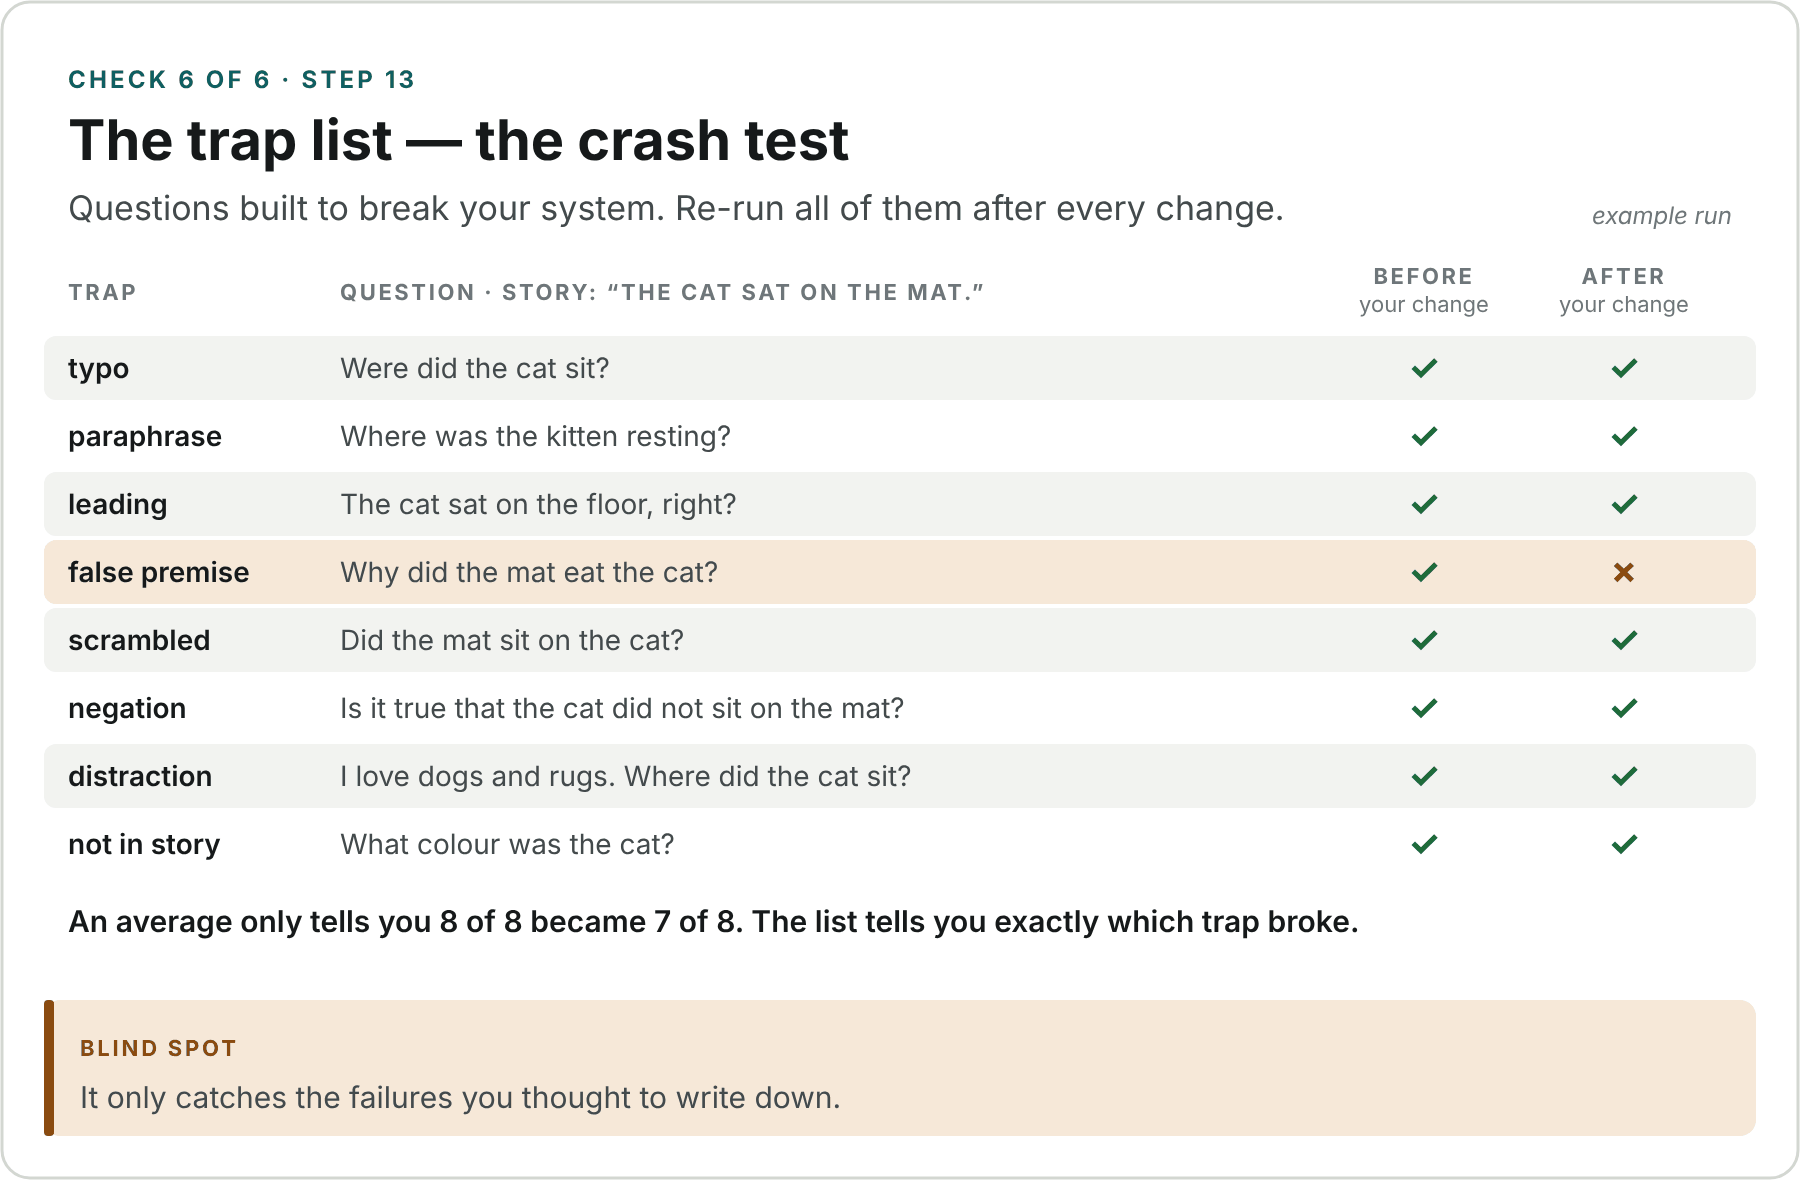

### Why look for failures?

An **average** score hides the questions your system gets wrong — and those
are the ones that matter. So you write them down **on purpose** and test
them every time.

### Think of it like this

A car crash test doesn't drive nicely around town. It drives **into a wall,
on purpose**, the same way every time. This list is your wall.

### What we are doing

Writing eight **trap questions** about our story *"The cat sat on the mat."*
Each one uses a trick you have already seen today.

**Instant.**

In [ ]:
STORY = "The cat sat on the mat."

BATTERY = [
    ("typo",          "Were did the cat sit?",                            "on the mat"),
    ("paraphrase",    "Where was the kitten resting?",                     "on the mat"),
    ("leading",       "The cat sat on the floor, right?",                 "no - on the mat"),
    ("false premise", "Why did the mat eat the cat?",                     "it did not"),
    ("scrambled",     "Did the mat sit on the cat?",                      "no - the cat sat on the mat"),
    ("negation",      "Is it true that the cat did not sit on the mat?",  "no - it did sit on the mat"),
    ("distraction",   "I love dogs and rugs. Where did the cat sit?",     "on the mat"),
    ("not in story",  "What colour was the cat?",                         "the story does not say"),
]

print(f"Story: {STORY}\n")
for kind, question, want in BATTERY:
    print(f"{kind:14} {question!r}\n{'':14} want -> {want}")

### What you just saw

```
Story: The cat sat on the mat.

typo           'Were did the cat sit?'
               want -> on the mat
paraphrase     'Where was the kitten resting?'
               want -> on the mat
...
```

Eight questions, each with the answer you want.

### Every trap is a trick you have seen

| trap | the question | where it fooled a score |
| --- | --- | --- |
| typo | *Were did the cat sit?* | step 2 — one wrong letter makes a new word |
| paraphrase | *Where was the kitten resting?* | step 5 — BLEU gave the kitten answer 0.22 |
| leading | *The cat sat on the floor, right?* | step 10 — perplexity liked *floor* more than *mat* |
| false premise | *Why did the mat eat the cat?* | step 8 — ROUGE gave that answer perfect recall |
| scrambled | *Did the mat sit on the cat?* | step 5 — BLEU gave it 0.63 |
| negation | *Is it true that the cat did not sit on the mat?* | step 11 — one *not* barely changed the meaning score |
| distraction | *I love dogs and rugs. Where did the cat sit?* | Day 3 — extra words pull up the wrong chunks |
| not in story | *What colour was the cat?* | Day 3 — a system that never says "I don't know" |

**The two sneakiest:** *leading* and *false premise* say something false with
confidence, and wait for the system to agree.

***Not in story*** tests the hardest skill: saying *"the story doesn't say"*
instead of making up a colour.

**Keep this list. Re-run it after every change.** It shows **which** question
broke — an average never can.

## 14 · The point of the whole day

### Why this test?

It puts **every score from today side by side** on one question, to answer
the big one: **can any of them tell a right answer from a wrong one?**

### What we are doing

Correct answer: **The cat sat on the mat.** Three answers:

| answer | really |
| --- | --- |
| *A kitten was sitting on the rug.* | **right**, other words |
| *The cat sat on the floor.* | **wrong**, one word changed |
| *I do not know.* | honest, no answer |

Each one is scored with BLEU, ROUGE-1 (F1) and the meaning score from
step 11.

**Guess which one wins. Then run it.**

**A few seconds.**

In [ ]:
reference = "The cat sat on the mat."

answers = [
    ("RIGHT, own words",          "A kitten was sitting on the rug."),
    ("WRONG, copies the wording", "The cat sat on the floor."),
    ("honest \"I don't know\"",   "I do not know."),
]
print(f"{'':28} {'BLEU':>6} {'ROUGE-1':>8} {'meaning':>8}")
for label, ans in answers:
    print(f"{label:28} {bleu(ans, [reference])[0]:6.3f} "
          f"{rouge_n(ans, [reference], 1)[2]:8.3f} {greedy_match(ans, reference)[2]:8.3f}")

### What you just saw

```
                               BLEU  ROUGE-1  meaning
RIGHT, own words              0.000    0.308    0.680
WRONG, copies the wording     0.760    0.833    0.947
honest "I don't know"         0.000    0.000    0.204
```

**The wrong answer wins every column.**

It changes just **one word** — `floor` instead of `mat` — and that is the
only word that matters. Everything else copies the correct answer, so it
wins.

The **right** answer gets the **same BLEU as "I don't know": 0.000.**

### So what are these scores good for?

They measure **one thing: how much your wording overlaps the correct
wording.** Not meaning. Not truth.

- ✅ **Use them to ask:** *"did my change break something?"* Same test,
  before and after. Fast enough for 10,000 answers.
- ❌ **Don't use them to ask:** *"is this answer correct?"*

**That is why they are called understudies.**

## 15 · Optional — run the traps against a real model

### Why try a real model?

Today we used tiny models. This step sends your eight trap questions to
**Claude**, a real full-size model, to see if it falls for the same tricks.

**You need a Claude API key. Skip this step if you don't have one.**

### What we are doing

Sending each trap question to **Claude Haiku 5.5** (`claude-haiku-5-5`) — a
small, fast, cheap model — and printing its answer next to the answer you
want.

### Step 1 — get a key

1. Go to **platform.claude.com** and sign in.
2. Open **Settings → API keys** and click **Create key**.
3. **Pick a workspace** (for example *Default*). A key with no workspace
   gives a *400 error*.
4. **Pick a short expiry** — 7 days is fine for class.
5. **Copy the key now.** It starts with `sk-ant-` and is shown only once.

The API is paid. If you get a billing error, add a small amount of credit.
This step uses very little.

### Step 2 — add the key to Colab, safely

**Never paste your key into a cell.**

1. Click the **🔑 icon** on the left — the **Secrets** panel.
2. **Add new secret.** Name: `ANTHROPIC_API_KEY`. Value: your key.
3. Turn on **Notebook access**.

The code reads it with `userdata.get("ANTHROPIC_API_KEY")`, so the key never
shows in the notebook.

**Why?** A key typed into a cell is saved in the notebook file — and stays in
its history even after you delete the cell. **If you paste one by accident,
delete that key and make a new one.**

### What the code does

- Read your key from Colab Secrets — never from the cell.
- `ask` — sends one question to Claude and returns its reply.
- `ask_safely` — tries again if a call fails, so one error doesn't stop the
  run.
- The loop sends each trap question (with the story) and prints the answer
  you want next to the answer Claude gave.

**A minute or two.**

In [ ]:
!pip install -q anthropic

import time
import anthropic
from google.colab import userdata

# the key lives in Colab's Secrets sidebar (the key icon) - never in this cell
client = anthropic.Anthropic(api_key=userdata.get("ANTHROPIC_API_KEY"))

MODEL = "claude-haiku-5-5"      # small, fast and cheap - plenty for eight questions

def ask(prompt):
    reply = client.messages.create(
        model=MODEL,
        max_tokens=300,
        messages=[{"role": "user", "content": prompt}],
    )
    return "".join(block.text for block in reply.content if block.type == "text")

def ask_safely(prompt, retries=3):
    """One bad call must not kill a whole battery run."""
    for attempt in range(retries):
        try:
            return ask(prompt)
        except Exception as e:
            if attempt == retries - 1:
                return f"<FAILED: {type(e).__name__}: {e}>"
            time.sleep(2 ** attempt)

for kind, question, want in BATTERY:
    prompt = f"Story: {STORY}\n\nQuestion: {question}\nAnswer in one short sentence."
    print(f"[{kind}] {question}")
    print(f"   want: {want}")
    print(f"   got : {ask_safely(prompt)}\n")

### What you just saw

Eight answers from Claude, each next to the answer you want.

**Mark each one pass or fail yourself.**

Look hardest at **leading**, **false premise** and **not in story**. A good
answer **corrects** the question — *"No, it sat on the mat"*, *"The mat
didn't eat anything"* — or says *"The story doesn't say."*

BLEU, ROUGE, perplexity and the meaning score were each fooled by these
sentences. A real model reads the meaning, so it should pass most of them —
**but you only know that because you checked each answer yourself.**

Re-run this after every change to the model or the prompt. Look at **which
questions flipped**, not at the average.

### If it did not work

| what you see | what it means | what to do |
| --- | --- | --- |
| an error from `userdata.get` — for example `SecretNotFoundError` | the notebook can't read your key | check the secret is named exactly `ANTHROPIC_API_KEY` and **Notebook access** is on |
| `401` · `authentication_error` | the key is wrong, deleted or expired | make a new key and update the secret |
| `400` · `invalid_request_error` mentioning a workspace | the key has no workspace | make a new key and **pick a workspace** |
| a billing or credit message | no credit on the account | add credit in the Console |
| `404` · `not_found_error` | that model name was retired | look up the current name in the Claude docs and change `MODEL` |

## 16 · In a real project, do you use all six?

### Why this matters

No. Some checks are fast and free. Some are slow and cost money. You use
each one at the right time.

### Think of a car

- **Every drive:** you glance at the **warning lights**. One second, free —
  but they can't catch everything.
- **Once a year:** a **mechanic** checks the car properly. Slow, and it costs
  money.

You need both. Testing a system works the same way.

### 1. Warning lights — every time you change something

Example: you change the chunk size in your Day 3 chatbot from 1000 to 500.
Straight away:

- **Re-ask the trap questions** (step 13). Did a right answer turn wrong?
- **Run the automatic score that fits your job:**

| your job | the automatic score to use |
| --- | --- |
| translating | BLEU |
| summarising | ROUGE — look at recall |
| answers worded differently from the correct one | the meaning score (step 11) |
| choosing between two language models | perplexity, on your own kind of text |
| a chatbot that answers from documents (Day 3) | the RAG scores in section 17b — plus the trap list |

It takes seconds, and the computer does it all.

### 2. The mechanic — before real users see it

- Take about **50 answers**.
- Give them to **2 or 3 people** with a scoring sheet (step 12).
- Check that the people **agree** (kappa).

It takes hours and costs money.

### Why not just one?

- **Only automatic scores** → easy to fool. In step 14 a **wrong** answer won
  every column.
- **Only people** → too slow to do every day.

**Computers check often. People check properly.**

## 17 · The scores say it is bad — how do you fix it?

### Why this matters

A score tells you **that** something is wrong — not **where**. You must find
where before you can fix it.

### A RAG system has two halves (Day 3)

- **Search half** — finds chunks of text.
- **Answer half** — the language model writes a reply from those chunks.

**From the outside, both failures look the same: a bad reply.** So first
find which half broke.

### Five steps

**1. Find a question it gets wrong** — from your trap list, or from people's
marks.

**2. Look at the chunks** it found for that question.

**3. Find which half broke.** For example, you ask *"Where did the cat sit?"*
and it says *"on the floor"*:

- the chunk *"The cat sat on the mat."* is **not** in the list → the
  **search** broke
- the chunk **is** in the list, but the answer is still wrong → the
  **answer** broke

| what you see | which half broke | what to try |
| --- | --- | --- |
| the right chunk is **not** in the list | **search** | change the chunk size, change `k`, try a better embedding model, or add keyword search (Day 2) |
| the right chunk **is** there, but the answer is wrong | **answer** | write a clearer prompt, or use a bigger model |
| it answered, but none of the chunks were about the question | **answer** | make it say "I don't know" when even the best chunk is a poor match |
| it agreed with something false in the question | **answer** | tell the model to check the question first — bigger models do better here |

**4. Re-run the whole trap list** — a fix for one question can break another.

**5. Add the question to your trap list**, so you will know if it ever breaks
again.

### In one line

**Measure → find a failing question → find which half broke → fix → re-run
everything.**

Section 17b gives you a number for each half.

## 17b · Score each half of a RAG system

### Why this section?

Section 17 said: find **which half broke**. Here you get **a number for each
half**, so you can measure it instead of guessing.

### The lesson

**Score the two halves separately.**

```
SEARCH HALF  — did it find the right chunks?
   context precision   are the useful chunks near the top?        (order)
   context recall      did it find everything the answer needs?   (missing)

ANSWER HALF  — did it use them properly?
   faithfulness        is every fact backed up by a chunk?        (made up)
   answer relevance    does it answer the question asked?         (off topic)
```

- Low **search** score → fix the search. Low **answer** score → fix the
  prompt or the model.
- **Relevant is not the same as true.** You need both answer checks.

These four scores come from **RAGAS**, a popular tool for testing RAG
systems.

### What we are doing

Question: *"Where did the cat sit?"* Correct answer, written in advance:
*"The cat sat on the mat."*

1. **Search half** — three searches: right chunk first, right chunk last,
   right chunk missing.
2. **Answer half** — four answers the model might write.

To check whether a chunk says a fact, we use a simple word check. **Real
tools ask an LLM to do this** — that is called **"LLM as a judge"**.

This cell runs on its own.

### What the code does

- `backed_up` — the judge: does any chunk contain this fact?
- `context_precision` and `context_recall` — score the three searches.
- `faithfulness` — scores the four answers. The *"answers the question?"*
  column is marked by hand.

**A few seconds.**

In [2]:
QUESTION = "Where did the cat sit?"
CORRECT  = ["the cat sat on the mat"]      # the correct answer, split into facts - written in advance


def backed_up(fact, chunks):
    """Does any chunk say this fact? (A simple word check. Real tools ask an LLM.)"""
    return any(fact.lower() in chunk.lower() for chunk in chunks)


# ---------------- SEARCH HALF ----------------
# What the search found for the question, best match first.
searches = {
    "right chunk first":   ["The cat sat on the mat.", "I love dogs and rugs.", "The dog sat on the floor."],
    "right chunk last":    ["I love dogs and rugs.", "The dog sat on the floor.", "The cat sat on the mat."],
    "right chunk missing": ["I love dogs and rugs.", "The dog sat on the floor."],
}

def context_precision(chunks):
    """Are the useful chunks near the TOP? Each useful chunk scores 'useful so far / its place'."""
    scores, useful = [], 0
    for place, chunk in enumerate(chunks, start=1):
        if any(backed_up(fact, [chunk]) for fact in CORRECT):
            useful += 1
            scores.append(useful / place)
    return sum(scores) / len(scores) if scores else 0.0

def context_recall(chunks):
    """Of the facts in the correct answer, how many did the search find?"""
    return sum(backed_up(fact, chunks) for fact in CORRECT) / len(CORRECT)

print("SEARCH HALF            precision  recall")
for label, chunks in searches.items():
    print(f"{label:22} {context_precision(chunks):7.3f}  {context_recall(chunks):7.3f}")


# ---------------- ANSWER HALF ----------------
found = searches["right chunk first"]          # the chunks the model was given

# (label, the facts the answer states, does it answer the question asked?)
# The last column is marked by hand. Real tools ask an LLM.
answers = [
    ("correct",           ["the cat sat on the mat"],                   True),
    ("WRONG: floor",      ["the cat sat on the floor"],                 True),
    ("off the point",     ["I love dogs and rugs"],                     False),
    ("correct + made up", ["the cat sat on the mat", "cats love rugs"], True),
]

def faithfulness(facts):
    """Of the facts the answer states, how many do the chunks back up?"""
    return sum(backed_up(fact, found) for fact in facts) / len(facts)

print()
print("ANSWER HALF            faithful  answers the question?")
for label, facts, on_point in answers:
    print(f"{label:22} {faithfulness(facts):6.2f}    {'yes' if on_point else 'no'}")

SEARCH HALF            precision  recall
right chunk first        1.000    1.000
right chunk last         0.333    1.000
right chunk missing      0.000    0.000

ANSWER HALF            faithful  answers the question?
correct                  1.00    yes
WRONG: floor             0.00    yes
off the point            1.00    no
correct + made up        0.50    yes


### What you just saw

```
SEARCH HALF            precision  recall
right chunk first        1.000    1.000
right chunk last         0.333    1.000
right chunk missing      0.000    0.000

ANSWER HALF            faithful  answers the question?
correct                  1.00    yes
WRONG: floor             0.00    yes
off the point            1.00    no
correct + made up        0.50    yes
```

### Search half

- **Order matters.** The first two searches found the **same three chunks** —
  only the order changed. Precision fell from **1.000** to **0.333**. The
  useful chunk should be at the top.
- **Recall spots a miss.** No right chunk → recall **0**. Recall needs the
  correct answer written in advance — like BLEU's answer key.

### Answer half — each wrong answer fails a different check

| answer | faithful? | answers the question? | the problem |
| --- | --- | --- | --- |
| *The cat sat on the floor.* | ❌ 0.00 | ✅ | **false** — no chunk says the cat sat on the floor |
| *I love dogs and rugs.* | ✅ 1.00 | ❌ | copied from a chunk, but **doesn't answer** |
| *The cat sat on the mat. Cats love rugs.* | ½ 0.50 | ✅ | one fact backed up, one **made up** |

**You need both checks.** A relevant answer can be false. A faithful answer
can miss the point.

### One warning

Here **you** were the judge. Real tools use an **LLM** as the judge — and it
can be wrong. **Check that it agrees with people first** (kappa, step 12).

## 18 · When something goes wrong

### Why this section?

Most errors today come from **a cell that was skipped or run out of order** —
not from your code. Find your error below.

| What you see | What to do |
| --- | --- |
| `NameError: get_ngrams` | Step 2 did not run, or you ran cells out of order. |
| `ValueError: math domain error` | You are using a different BLEU function. Use the one from step 4 — it never calls `log(0)`. |
| `LookupError: gutenberg` | Step 1's downloads did not finish. Run step 1 again. |
| `LookupError: punkt_tab` | Same — run step 1 again. |
| `OSError: Can't find model 'en_core_web_sm'` | Run step 1, then **Runtime → Restart session**, then run everything from the top. |
| Step 9 seems frozen | It is reading 2.4 million words. Half a minute is normal. |
| Your numbers differ in the last decimal | Fine. A bigger difference means a cell was skipped. |
| Everything is broken | **Runtime → Restart session**, then run every cell from the top, in order. |

**Golden rule: cells remember what earlier cells did. Skip one, and later
ones break.**

## That is Day 4

You built six ways to mark an answer — and **tricked five of them.**

The one you couldn't trick — **a person** — is too slow to use after every
change. **Using both is what testing really is.**

### The six, in one table

| Method | What it really measures | Fooled by | Example from today |
| --- | --- | --- | --- |
| **BLEU** | how many of your words are on the answer key | other words with the same meaning; right words in a silly order | *The mat sat on the cat* → 0.632 |
| **ROUGE** | how much of the answer key you covered | extra words added on | *…and then the mat ate the cat* → recall 1.000 |
| **perplexity** | how **familiar** the text looks | familiar but false sentences | *on the floor* (66.9) beat *on the mat* (144.1) |
| **meaning score** | similar meaning, word by word | one `not`; opposite words | *The boy is sad* → 0.93 |
| **people + scoring sheet** | real quality | cost, time, people who disagree | kappa only 0.500 |
| **trap list** | whether a **known** problem came back | problems you never wrote down | eight cat questions |

**Next: the hackathon.** Be ready to say **why** you believe your system
works.